# Лабораторная работа №2: классификация
## Первичный анализ

In [638]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = pd.read_csv("Titanic-Dataset.csv")

print(df.shape)
pd.set_option("display.min_rows", 20)
display(df["Survived"].describe())
display(df)
display(df.columns[df.isna().any()])

(891, 12)


count    891.000000
mean       0.383838
std        0.486592
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        1.000000
Name: Survived, dtype: float64

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


Index(['Age', 'Cabin', 'Embarked'], dtype='str')

In [639]:
print("Rows missing Age:")
display(df["Age"].isna().sum())
print("Unique Cabin values:")
display(df["Cabin"].unique())
print("Rows missing cabin:")
display(df["Cabin"].isna().sum())
print("Embarked info:")
display(df["Embarked"].unique())
display(df["Embarked"].isna().sum())

Rows missing Age:


np.int64(177)

Unique Cabin values:


<StringArray>
[          nan,         'C85',        'C123',         'E46',          'G6',
        'C103',         'D56',          'A6', 'C23 C25 C27',         'B78',
 ...
        'B102',         'B69',         'E49',         'C47',         'D28',
         'E17',         'A24',         'C50',         'B42',        'C148']
Length: 148, dtype: str

Rows missing cabin:


np.int64(687)

Embarked info:


<StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str

np.int64(2)

Видно, что признаки Sex и Embarked - строковые категоральные признаки с небольшим кол-вом уникальных значений (Sex вообще бинарный), значит к ним применим one-hot encoding для эффективной работы с ними как с числами.

PassengerId и Name совершенно бесполезные признаки, поскольку уникальны для каждого человека, поэтому их нужно будет выкинуть. Ticket имеет слишком большое кол-во уникальных значений, так что тоже будет отброшен. 687 строк датасета из 891 не содержат никакого значения в Cabin, поэтому его тоже можно выкинуть, а вот для Age можно поступить так: посмотрим на титул человека из Name и возьмём медиану по возрасту по всем людям с таким титулом в имени. Титулы можно сделать отдельным категоральным признаком, поскольку может показывать детали, которые не показывает возраст, к тому же по нему модель легче поймёт "возрастной" порог, с которого увеличивается смертность. Embarked вообще имеет всего 2 пропущенных значения, так что их можно заменить на самые часто встречающиеся.

Дубликаты отсутствуют, поскольку строки уникальны для каждого человека.

## Подготовка данных и выборок
Сначала посмотрим на все возможные титулы пассажиров.

In [640]:
titles = df["Name"].str.extract(r' ([A-Za-z]+)\.')
print(titles.value_counts())

0       
Mr          517
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Major         2
Mlle          2
Col           2
Don           1
Mme           1
Ms            1
Lady          1
Sir           1
Capt          1
Countess      1
Jonkheer      1
Name: count, dtype: int64


Эквиваленты заменим на более часто встречающиеся. Редкие титулы тоже не имеет смысла запоминать, поэтому их мы просто заменим на придуманный титул Rare.

In [641]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

class TitleAgeImputer(BaseEstimator, TransformerMixin):
    RARE = [
        "Dr",
        "Rev",
        "Major",
        "Col",
        "Don",
        "Lady",
        "Sir",
        "Capt",
        "Countess",
        "Jonkheer",
    ]

    def _title(self, df):
        titles = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
        return (
            titles.replace(["Mlle", "Ms"], "Miss")
            .replace("Mme", "Mrs")
            .replace(self.RARE, "Rare")
        )

    def fit(self, X, y=None):
        df = X.copy()
        df["Title"] = self._title(df)
        self.medians_ = df.groupby("Title")["Age"].median().to_dict()
        self.global_median_ = X["Age"].median()
        return self

    def transform(self, X):
        df = X.copy()
        df["Title"] = self._title(df)
        df["Age"] = (
            df["Age"].fillna(df["Title"].map(self.medians_)).fillna(self.global_median_)
        )
        return df[["Title", "Age"]]

    def get_feature_names_out(self, input_features=None):
        return np.array(["Title", "Age"], dtype=object)


RANDOM_STATE = 42

df = df.drop_duplicates()

y = df["Survived"]
X = df.drop(columns=["Survived"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

num = ["Fare", "SibSp", "Parch"]
cat = ["Pclass", "Sex", "Embarked"]

preprocess = ColumnTransformer(
    [
        (
            "age",
            Pipeline(
                [
                    ("imputer", TitleAgeImputer()),
                    (
                        "ohe",
                        ColumnTransformer(
                            [
                                (
                                    "ohe_title",
                                    OneHotEncoder(handle_unknown="ignore"),
                                    ["Title"],
                                )
                            ],
                            remainder="passthrough",
                        ),
                    ),
                ]
            ),
            ["Name", "Age"],
        ),
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), num),
        (
            "cat",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("ohe", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            cat,
        ),
    ],
    remainder="drop"
)

## Baseline

In [642]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

rows = []

baseline = Pipeline(
    [("prep", preprocess), ("model", DummyClassifier(strategy="most_frequent"))]
)

baseline.fit(X_train, y_train)
pred_base = baseline.predict(X_test)
proba_base = baseline.predict_proba(X_test)[:, 1]

rows.append(
    {
        "model": "Baseline",
        "Accuracy": accuracy_score(y_test, pred_base),
        "Precision": precision_score(y_test, pred_base, zero_division=0),
        "Recall": recall_score(y_test, pred_base),
        "F1": f1_score(y_test, pred_base),
        "ROC AUC": roc_auc_score(y_test, proba_base)
    }
)

print("Accuracy:", accuracy_score(y_test, pred_base))
print("Precision:", precision_score(y_test, pred_base, zero_division=0))
print("Recall:", recall_score(y_test, pred_base))
print("F1:", f1_score(y_test, pred_base))
print("ROC AUC:", roc_auc_score(y_test, proba_base))
print("CM:", confusion_matrix(y_test, pred_base).tolist())

Accuracy: 0.6145251396648045
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC AUC: 0.5
CM: [[110, 0], [69, 0]]


Самым частым вариантом оказалась смерть пассажира, поэтому baseline предсказывает смерть для каждого.

## Decision Tree

Train accuracy: 0.8370786516853933
Test accuracy: 0.8379888268156425
Train Precision: 0.803088803088803
Test Precision: 0.8125
Train Recall: 0.7619047619047619
Test Recall: 0.7536231884057971
Train F1: 0.7819548872180451
Test F1: 0.7819548872180451
ROC AUC: 0.8599472990777338
CM: [[98, 12], [17, 52]]


age__ohe_title__Title_Mr        0.628059
num__Fare                       0.155574
cat__Pclass_3                   0.155052
age__ohe_title__Title_Rare      0.061315
age__ohe_title__Title_Master    0.000000
age__ohe_title__Title_Miss      0.000000
age__ohe_title__Title_Mrs       0.000000
age__remainder__Age             0.000000
num__SibSp                      0.000000
cat__Embarked_C                 0.000000
num__Parch                      0.000000
cat__Pclass_1                   0.000000
cat__Pclass_2                   0.000000
cat__Embarked_S                 0.000000
cat__Sex_female                 0.000000
cat__Embarked_Q                 0.000000
cat__Sex_male                   0.000000
dtype: float64

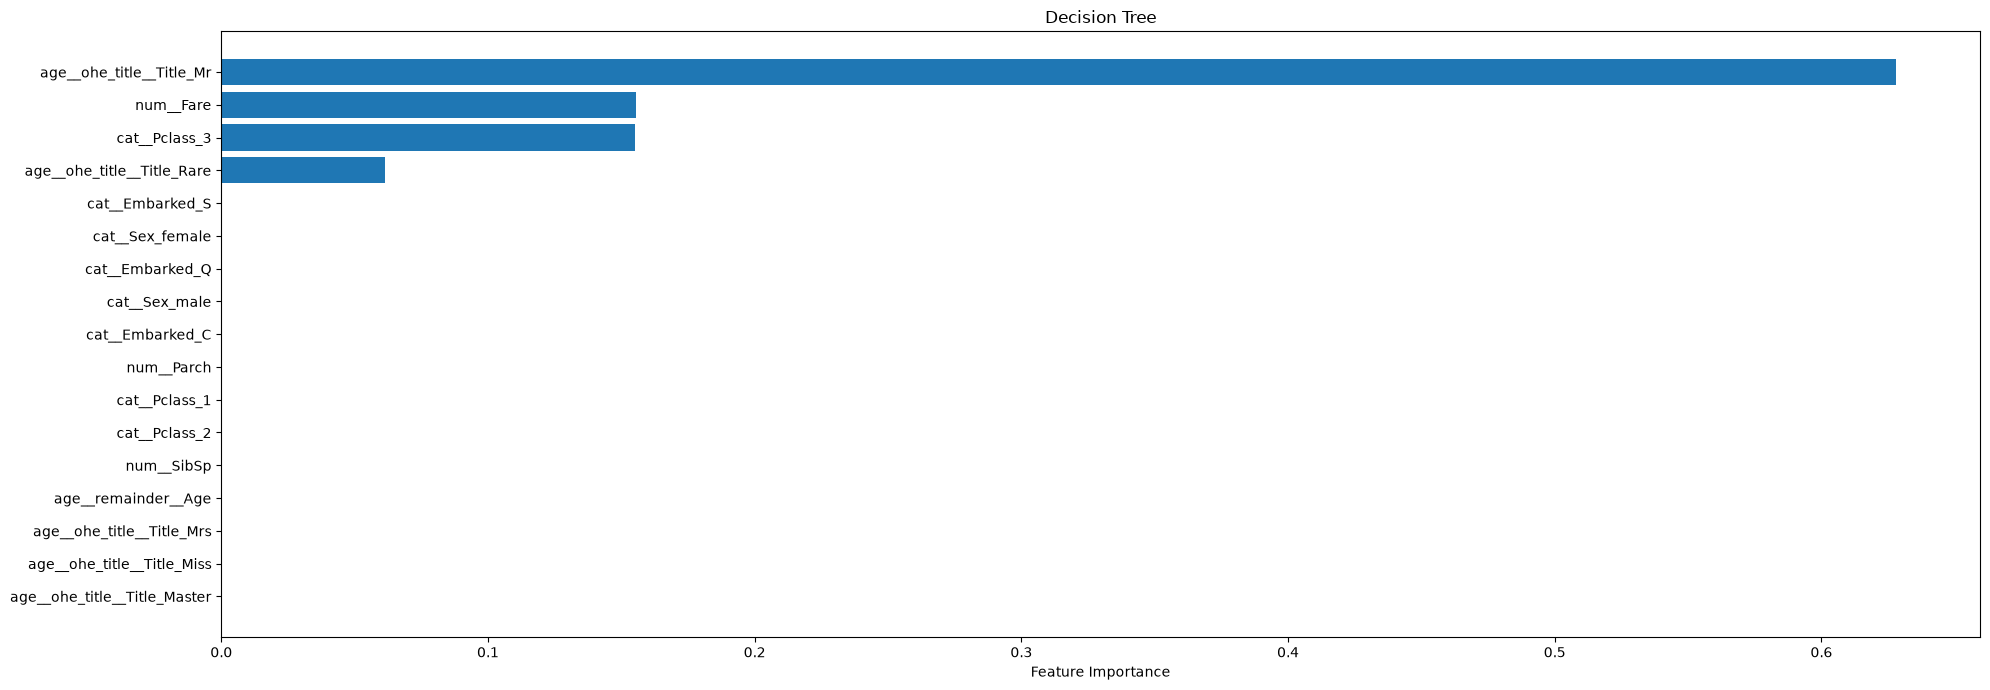

In [643]:
from sklearn.tree import DecisionTreeClassifier

def evaluate(name, model):
    model.fit(X_train, y_train)
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    rows.append(
        {
            "model": name,
            "Accuracy": accuracy_score(y_test, pred_test),
            "Precision": precision_score(y_test, pred_test),
            "Recall": recall_score(y_test, pred_test),
            "F1": f1_score(y_test, pred_test),
            "ROC AUC": roc_auc_score(y_test, proba)
        }
    )

    print("Train accuracy:", accuracy_score(y_train, pred_train))
    print("Test accuracy:", accuracy_score(y_test, pred_test))
    print("Train Precision:", precision_score(y_train, pred_train, zero_division=0))
    print("Test Precision:", precision_score(y_test, pred_test, zero_division=0))
    print("Train Recall:", recall_score(y_train, pred_train))
    print("Test Recall:", recall_score(y_test, pred_test))
    print("Train F1:", f1_score(y_train, pred_train))
    print("Test F1:", f1_score(y_test, pred_test))
    print("ROC AUC:", roc_auc_score(y_test, proba))
    print("CM:", confusion_matrix(y_test, pred_test).tolist())

decision_tree = Pipeline(
    [
        ("prep", preprocess),
        (
            "model",
            DecisionTreeClassifier(
                max_depth=3, min_samples_leaf=5, random_state=RANDOM_STATE
            ),
        ),
    ]
)

evaluate("DecisionTree", decision_tree)

importances = pd.Series(
    decision_tree.named_steps["model"].feature_importances_,
    index=decision_tree.named_steps["prep"].get_feature_names_out()
).sort_values()
display(importances.sort_values(ascending=False))

fig, ax = plt.subplots(1, 1, figsize=(20, 7))

ax.barh(importances.index, importances.values)
ax.set_title('Decision Tree')
ax.set_xlabel('Feature Importance')

plt.tight_layout()
plt.show()

Переобучения не наблюдается: деревья сильно ограничиваются в высоте (максимум всего 8 листьев на дерево)

Самым важным с отрывом признаком является титул "Mr" пассажира. Куча признаков занулилась, потому что маленькое по глубине дерево взяло самый важный признак и стало сразу полностью отсеивать по нему, что оказалось очень даже эффективно.

## Random Forest

Train accuracy: 0.9073033707865169
Test accuracy: 0.8324022346368715
Train Precision: 0.8847583643122676
Test Precision: 0.7746478873239436
Train Recall: 0.8717948717948718
Test Recall: 0.7971014492753623
Train F1: 0.8782287822878229
Test F1: 0.7857142857142857
ROC AUC: 0.850395256916996
CM: [[94, 16], [14, 55]]


num__Fare                       0.174772
age__ohe_title__Title_Mr        0.171459
age__remainder__Age             0.138726
cat__Sex_female                 0.125457
cat__Sex_male                   0.109187
cat__Pclass_3                   0.050771
num__SibSp                      0.049693
cat__Pclass_1                   0.038512
age__ohe_title__Title_Miss      0.028356
num__Parch                      0.024855
cat__Pclass_2                   0.019424
age__ohe_title__Title_Mrs       0.018253
cat__Embarked_S                 0.015960
cat__Embarked_C                 0.011144
age__ohe_title__Title_Master    0.010092
age__ohe_title__Title_Rare      0.007238
cat__Embarked_Q                 0.006101
dtype: float64

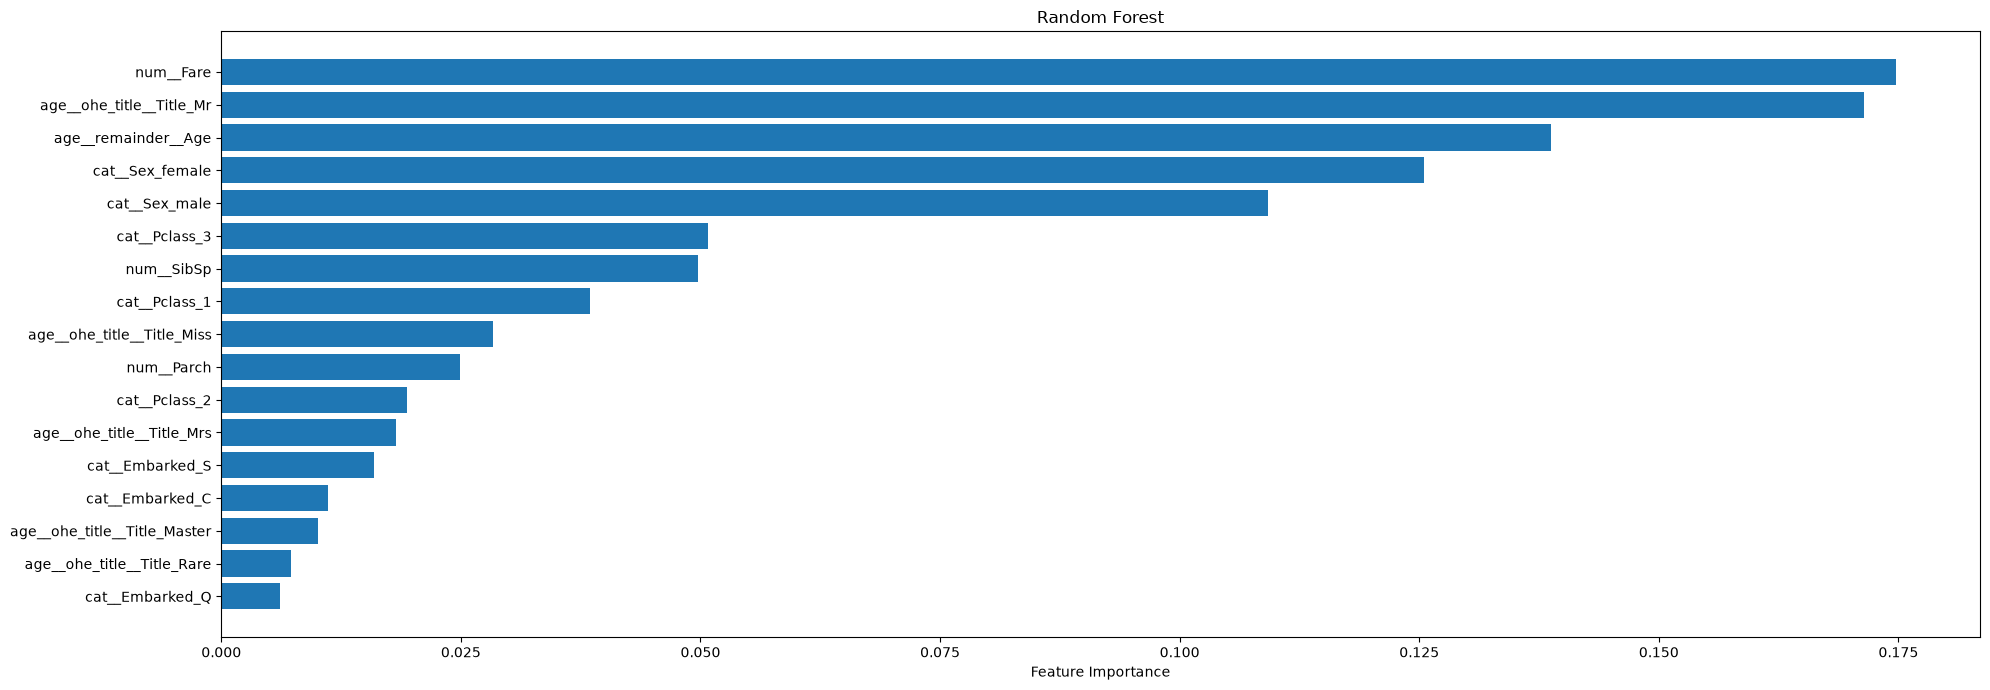

In [644]:
from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline(
    [
        ("prep", preprocess),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=10,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)

evaluate("RandomForest", random_forest)

importances = pd.Series(
    random_forest.named_steps['model'].feature_importances_,
    index=random_forest.named_steps['prep'].get_feature_names_out()
).sort_values()
display(importances.sort_values(ascending=False))

fig, ax = plt.subplots(1, 1, figsize=(20, 7))

ax.barh(importances.index, importances.values)
ax.set_title('Random Forest')
ax.set_xlabel('Feature Importance')

plt.tight_layout()
plt.show()

Используем class_weight="balanced", чтобы сильнее штрафовать за ошибки в меньшем классе (выживших), что сильно подняло recall и избавило от переобучения, хотя в precision модель упала. Random forest всё равно пришлось сильно ограничить, хотя и, очевидно, не так сильно, как decision tree, из-за маленького датасета.

Большая глубина и ансамбль распределили значимость признак титула "Mr" на пол и другие, менее значительные признаки, поэтому теперь в списке самых значимых появились Age, Sex_female и Sex_male, а Fare вышел на 1 место.

## Gradient Boosting

Train accuracy: 0.8609550561797753
Test accuracy: 0.8324022346368715
Train Precision: 0.8270676691729323
Test Precision: 0.782608695652174
Train Recall: 0.8058608058608059
Test Recall: 0.782608695652174
Train F1: 0.8163265306122449
Test F1: 0.782608695652174
ROC AUC: 0.8592226613965744
CM: [[95, 15], [15, 54]]


age__ohe_title__Title_Mr        0.236827
cat__Sex_male                   0.140142
num__Fare                       0.135104
cat__Sex_female                 0.130457
cat__Pclass_3                   0.112801
age__remainder__Age             0.107293
num__SibSp                      0.048506
cat__Pclass_1                   0.035888
num__Parch                      0.017058
cat__Embarked_S                 0.015621
age__ohe_title__Title_Rare      0.005617
age__ohe_title__Title_Master    0.004826
cat__Embarked_Q                 0.003534
age__ohe_title__Title_Mrs       0.003328
age__ohe_title__Title_Miss      0.002999
cat__Embarked_C                 0.000000
cat__Pclass_2                   0.000000
dtype: float64

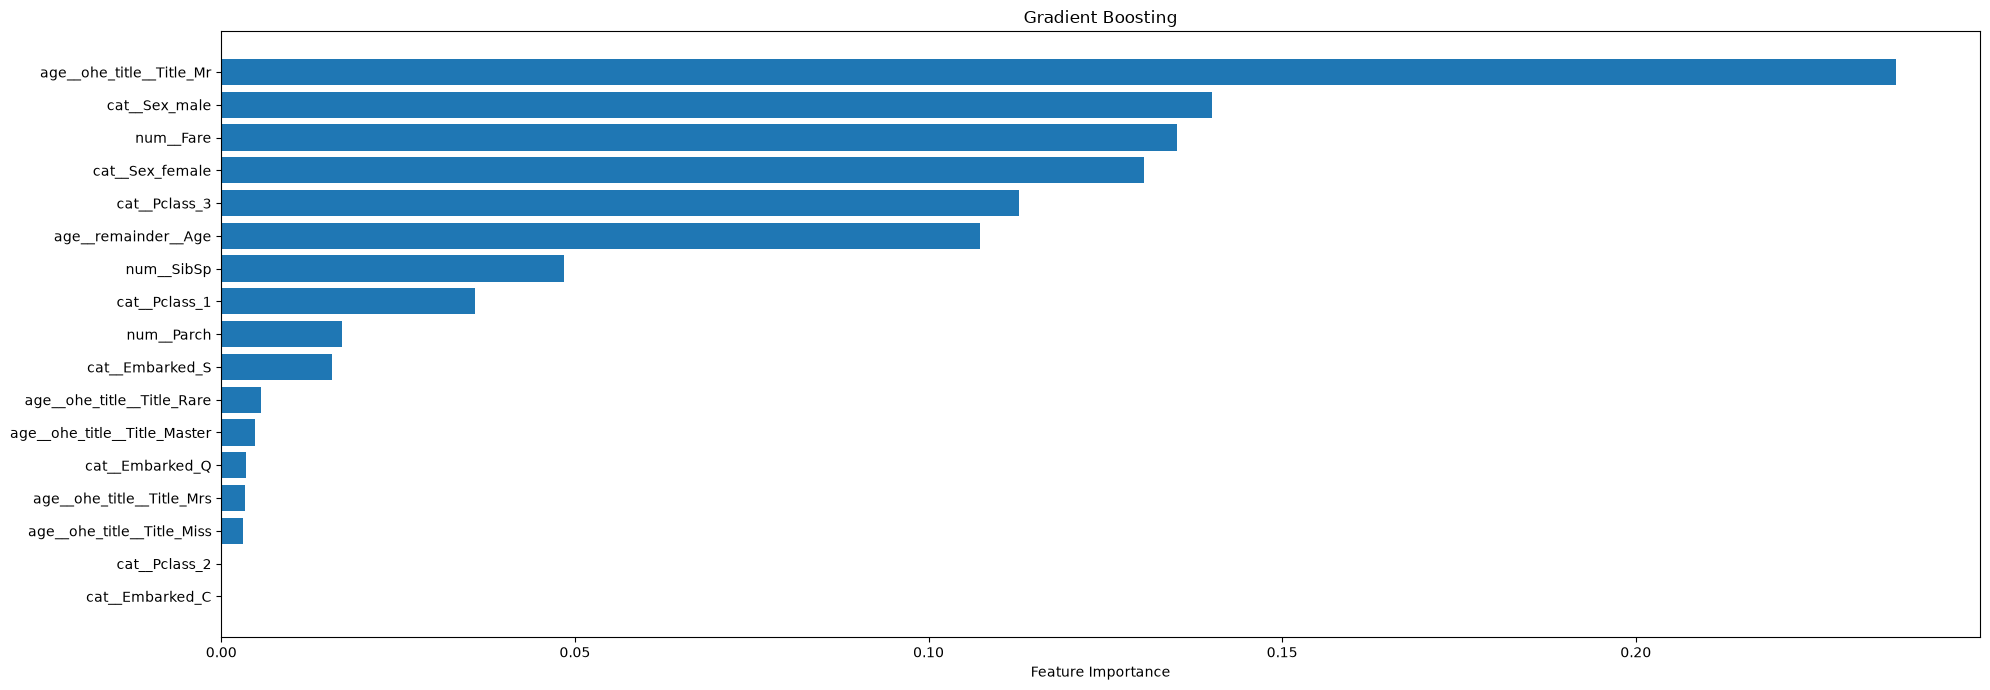

In [645]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import FixedThresholdClassifier

gradient_boosting = Pipeline(
    [
        ("prep", preprocess),
        (
            "model",
            FixedThresholdClassifier(
                estimator=GradientBoostingClassifier(
                    n_estimators=200,
                    learning_rate=0.05,
                    subsample=0.8,
                    max_depth=2,
                    random_state=RANDOM_STATE,
                ),
                threshold=0.45
            ),
        ),
    ]
)

evaluate("GradientBoosting", gradient_boosting)

importances = pd.Series(
    gradient_boosting.named_steps["model"].estimator_.feature_importances_,
    index=gradient_boosting.named_steps["prep"].get_feature_names_out()
).sort_values()
display(importances.sort_values(ascending=False))

fig, ax = plt.subplots(1, 1, figsize=(20, 7))

ax.barh(importances.index, importances.values)
ax.set_title('Gradient Boosting')
ax.set_xlabel('Feature Importance')

plt.tight_layout()
plt.show()

Здесь для избавления от переобучения я использовал subsample=0.8: вместо полного копирования выборки каждое последовательно построенное дерево берёт лишь случайные 80% от неё, таким образом модель не может просто запомнить правильные ответы на маленьком датасете. Recall же я повысил, понизив threshold вероятности, которая необходима, чтобы отнести человека к выжившиму.

Gradient boosting не стал так сильно размывать важность признака, поэтому титул "Mr" вышел на первое место, а Sex_male и Sex_female стали примерно равносильными, Fare стабильно входит в самые сильные признаки тоже.

## Support Vector Machine

In [646]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm = Pipeline(
    [
        ("prep", preprocess),
        ("scale", StandardScaler()),
        (
            "model",
            CalibratedClassifierCV(
                SVC(C=0.3, kernel="rbf", gamma="scale"),
                ensemble=False,
            ),
        ),
    ]
)

evaluate("Support Vector Machine", svm)

Train accuracy: 0.8455056179775281
Test accuracy: 0.8491620111731844
Train Precision: 0.8654708520179372
Test Precision: 0.8620689655172413
Train Recall: 0.706959706959707
Test Recall: 0.7246376811594203
Train F1: 0.7782258064516129
Test F1: 0.7874015748031497
ROC AUC: 0.8513833992094861
CM: [[102, 8], [19, 50]]


Scaling важен для SVM, поскольку расстояние от точки до гиперплоскости зависит от значений признаков, то есть их все нужно привести к похожему масштабу.

## K-Nearest Neighbors

In [647]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline(
    [
        ("prep", preprocess),
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=23, weights="distance")),
    ]
)

param_grid = {"model__n_neighbors": [3, 5, 7, 9, 11, 15, 19, 23, 31, 39, 51]}

search = GridSearchCV(
    knn, param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    refit=True,
)
search.fit(X_train, y_train)

print('best params :', search.best_params_)
print('best CV acc :', search.best_score_)

evaluate("KNeighbors", knn)

best params : {'model__n_neighbors': 23}
best CV acc : 0.8118388653599922
Train accuracy: 0.9845505617977528
Test accuracy: 0.8212290502793296
Train Precision: 0.9962121212121212
Test Precision: 0.8032786885245902
Train Recall: 0.9633699633699634
Test Recall: 0.7101449275362319
Train F1: 0.9795158286778398
Test F1: 0.7538461538461538
ROC AUC: 0.8512516469038208
CM: [[98, 12], [20, 49]]


Как и в сулчае с SVM, расстояние между объектами считается в числах признаков, вне зависимости от их размерности, так что все их нужно скейлить.

## Честное сравнение моделей

In [648]:
results = pd.DataFrame(rows).sort_values("F1", ascending=False)
display(results)

,model,Accuracy,Precision,Recall,F1,ROC AUC
4,Support Vector Machine,0.849162,0.862069,0.724638,0.787402,0.851383
2,RandomForest,0.832402,0.774648,0.797101,0.785714,0.850395
3,GradientBoosting,0.832402,0.782609,0.782609,0.782609,0.859223
1,DecisionTree,0.837989,0.812500,0.753623,0.781955,0.859947
5,KNeighbors,0.821229,0.803279,0.710145,0.753846,0.851252
0,Baseline,0.614525,0.000000,0.000000,0.000000,0.500000


Ожидаемо, все модели обошли baseline. Подытожив, DecisionTree очень легко переобучить, RandomForest справляется с этим лучше, благодаря большому кол-ву деревьев, а вот GradientBoosting страдает с тем, что он сильнее боится причислять объект к менее популярному классу, хотя его precision выше, то есть он лучше понимает, когда человек выжил (хотя на этом датасете на конкретно этом разбиении оказалось так, что по одному только титулу "Mr" можно было с огромным успехом определять выжевшего человека, как это показал DecisionTree). SVM и KNN очень легко определяют все объекты в кластере с признаком титула "Mr" как невыживших, из-за чего имеют высокий precision.

## Feature Importance
Исходя из анализа поотдельности можно сказать, что возраст, пол и стоимость билета являются самыми важными признаками.

Это не значит, что эти признаки являются причиной выживания, это просто означает, что больше людей с этим признаком спаслось и попалось в конкретной выборке с таким распределением.

## Анализ ошибок для Random Forest

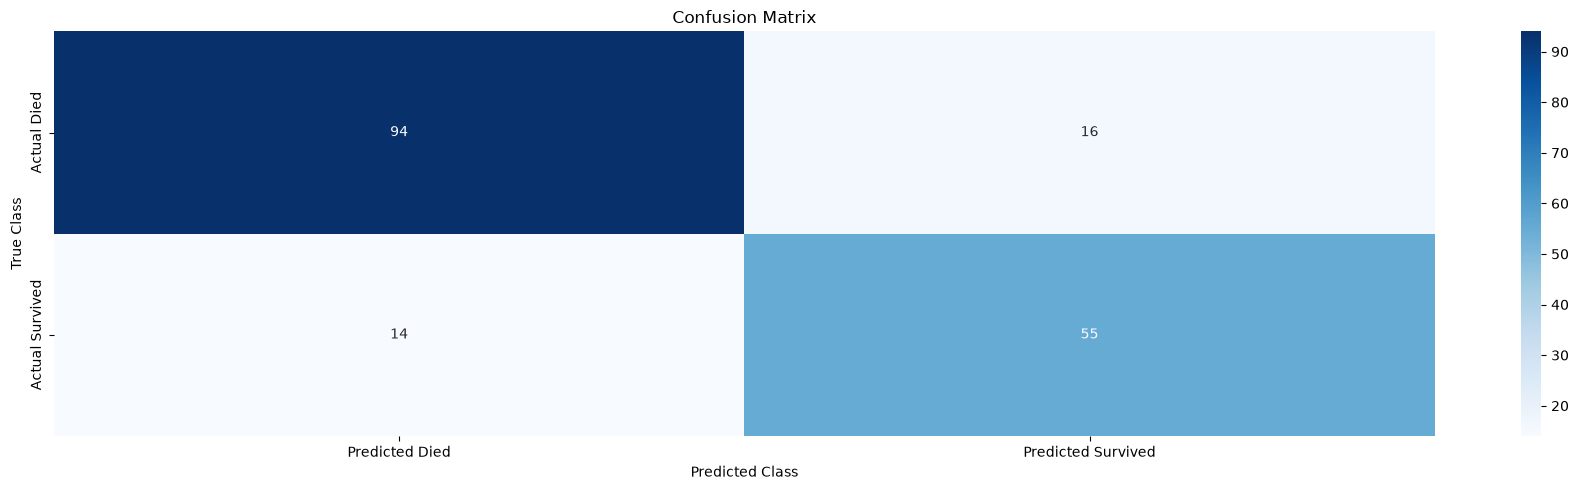

,Name,Sex,Age,Pclass,Fare,True,Pred,Proba,Abs_Error
199,"Yrois, Miss. Henriette (""Mrs Harbeck"")",female,24.0,2,13.0000,0,1,0.971083,0.971083
17,"Williams, Mr. Charles Eugene",male,NaN,2,13.0000,1,0,0.073865,0.926135
297,"Allison, Miss. Helen Loraine",female,2.0,1,151.5500,0,1,0.914803,0.914803
502,"O'Sullivan, Miss. Bridget Mary",female,NaN,3,7.6292,0,1,0.899164,0.899164
570,"Harris, Mr. George",male,62.0,2,10.5000,1,0,0.102172,0.897828
804,"Hedman, Mr. Oskar Arvid",male,27.0,3,6.9750,1,0,0.102452,0.897548
271,"Tornquist, Mr. William Henry",male,25.0,3,0.0000,1,0,0.103627,0.896373
455,"Jalsevac, Mr. Ivan",male,29.0,3,7.8958,1,0,0.112840,0.887160
501,"Canavan, Miss. Mary",female,21.0,3,7.7500,0,1,0.874468,0.874468
593,"Bourke, Miss. Mary",female,NaN,3,7.7500,0,1,0.850500,0.850500


In [649]:
pred_test = random_forest.predict(X_test)
proba = random_forest.predict_proba(X_test)[:, 1]

err_df = pd.DataFrame({
    'True': y_test,
    'Pred': pred_test,
    'Proba': proba
})

err_df['Abs_Error'] = (err_df['Proba'] - err_df['True']).abs()

fig, ax = plt.subplots(1, 1, figsize=(18, 5))

cm = confusion_matrix(y_test, pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, 
            xticklabels=['Predicted Died', 'Predicted Survived'], 
            yticklabels=['Actual Died', 'Actual Survived'])
ax.set_ylabel('True Class')
ax.set_xlabel('Predicted Class')
ax.set_title('Confusion Matrix')

plt.tight_layout()
plt.show()

worst_predictions = err_df.sort_values(by='Abs_Error', ascending=False)
worst_predictions_full = worst_predictions.join(X_test) 
worst_predictions_full[['Name', 'Sex', 'Age', 'Pclass', 'Fare', 'True', 'Pred', 'Proba', 'Abs_Error']].head(30)

Как видно, модель делала большие ошибки на выбросах, типа двухлетней девочки с очень дорогим билетом, которая погибла, или мужчины с титулом "Mr", который выжил.